<a href="https://colab.research.google.com/github/pi1024/PythonTutorial4/blob/main/IntroMatplotlibSeaborn_part1_1016.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

IJC445 Data Visualisation Week 3 Lab
# Introduction to Matplotlib and seaborn (part 1)

**This is a read-only version. To get started with your own copy: "File" -> "Save a copy in Drive"**

**Prerequisites:** You should have learned the foundation of Python before starting this worksheet.

While you will also use Python in other module, in this worksheet (and this module) we focus on how we can use Python to *create visualisation* using different Python libraries. The learning objectives are:

*   Introduce Matplotlib and where it sits among Python's plotting
    libraries
*   Build basic visualisations from a real dataset
*   Modify the aesthetics of a plot: lines, markers and colours
*   Incorporate titles, captions and legends into plots
*   Save a chart as a file you can use somewhere else

Along the way you will also collect live data from the World Bank API
and meet the most common ways a chart goes wrong.

# 1. Introduction


In this session, we will focus on mastering some essential visualisation techniques using the strengths of [matplotlib](https://matplotlib.org).  Let's start by installing and importing these libraries  using the `pip` command. For fundamental plots like line, bar, pie , we will use the `matplotlib.pyplot` module, often imported as `plt`. In addition, we need to install the Pandas and Numpy libraries for later use.

These libraries should be already available on Colab, but you might need to install them as follows if you run Python locally.

In [ ]:
!pip install matplotlib
!pip install pandas
!pip install numpy

# 2. Matplotlib

**[Matplotlib](https://matplotlib.org)** is the oldest and most widely
used plotting library in Python. Almost every other Python charting
library is either built on top of it or designed to look like it, so
learning Matplotlib first means the rest come more easily.

You will meet others later in the module. **Seaborn** sits on top of
Matplotlib and makes statistical charts short to write. For now we work with Matplotlib directly,
because it is the one that shows you what a chart is actually made of.


In [ ]:
# pyplot is the part of Matplotlib you draw with;
# plt is the conventional short name for it
import matplotlib.pyplot as plt

## 2.1 Create a new figure

We can create a new figure with the `.figure()` method.
This step is not mandatory and, if you do not instantiate a new figure, one will be created with the default parameters.

In [ ]:
# an empty figure with no Axes.
# figsize is given in INCHES, (width, height), and dpi is dots per
# inch, so this one is 6 x 4 inches at 100 dots per inch = 600 x 400
# pixels. Raise dpi when you save a chart for print, not here.
fig = plt.figure(figsize=(6, 4), dpi=100)

<Figure size 600x400 with 0 Axes>

In Matplotlib, creating plots can be approached in several ways, depending on the complexity and requirements of your visualisation. Two common methods are using `plt.subplots()` and `plt.plot()`. Each serves different purposes and fits different scenarios of plot creation.

### Option 1. Using `plt.subplots()`

The function `plt.subplots()` is very handy when you need to create a figure that includes one or more subplots: several axes in a single figure. This method provides an efficient way to create and manage multiple plots on a grid layout.

- **Functionality**: `plt.subplots()` simplifies the process of adding subplots to a figure. It returns a tuple containing a `Figure` object and an `Axes` object or an array of `Axes` objects.
- **Flexibility**: You can specify the number of rows and columns in the grid layout, making it ideal for creating complex visualization layouts in a single figure.


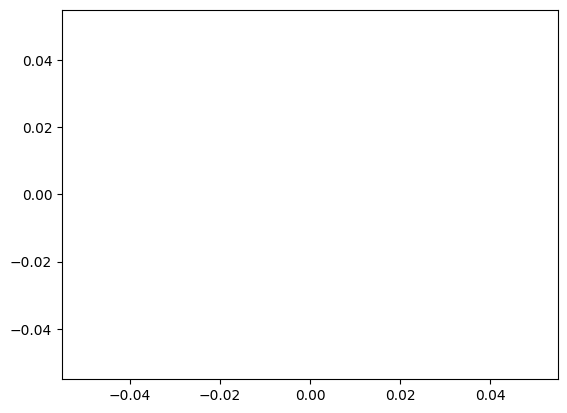

In [ ]:
# Example of plt.subplots()

# Create a figure with a single subplot
fig, ax = plt.subplots()

# Plot data on the axes
ax.plot()

# Show the plot
plt.show()

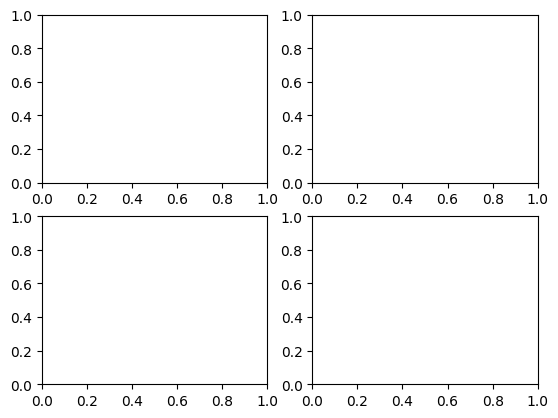

In [ ]:
# a figure with a 2x2 grid of Axes
fig, ax = plt.subplots(2, 2)
# Show the plot
plt.show()

### Option 2. Using `plt.plot()`

On the other hand, `plt.plot()` is a function used to plot y versus x as lines and/or markers. This function is generally used when you need a quick and easy way to plot data on the current axes in the current figure.

- **Functionality**: `plt.plot()` automatically gets the current axes with `plt.gca()` and uses it to plot the data. If no axes exist, it creates them.
- **Simplicity**: Best for quick plots and simple use cases.

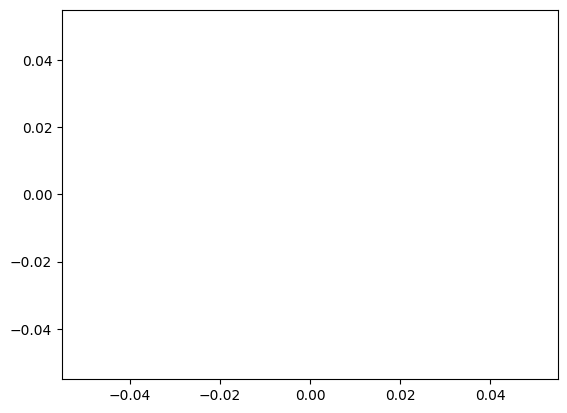

In [ ]:
# Plot an empty figure (implicitly creates a figure and an axes)
plt.plot()
plt.show()

### Comparison and When to Use Each

| Feature  | plt.plot()                                   | plt.subplots()                                  |
|----------|--------------------------------------------|-------------------------------------------------|
| Function | Creates visual elements on existing axes   | Manages subplot layout and organization         |
| Purpose  | Plots your data                            | Arranges multiple plots within a figure         |
| Usage    | It creates axes if none exist         | Takes arguments defining subplot grid layout    |
| Arguments| Data points                                | nrows, ncols, index (for subplot placement)     |
| Returns  | Returns a list of Line2D objects                                       | A tuple of (Figure, Axes)    |



In summary, `plt.subplots()` is more versatile and powerful for creating complex layouts and managing multiple plots, whereas `plt.plot()` is convenient for less complex plotting tasks that require fewer lines of code and less customization. Each serves its purpose in the broader toolkit provided by Matplotlib, allowing you to choose based on your specific needs and the complexity of your visualization task.

## 2.2 Plotting examples

We will initiate our exploration of data visualisation by focusing on line charts, they are a fantastic starting point for exploring data visualisation. **Line charts** represent information through a sequence of data points linked by continuous straight lines. These charts offer the flexibility to tailor various visual attributes, such as the lines and markers shape, size, and color, enhancing the overall readability and visual appeal of the data presented.



### Plot function with one list

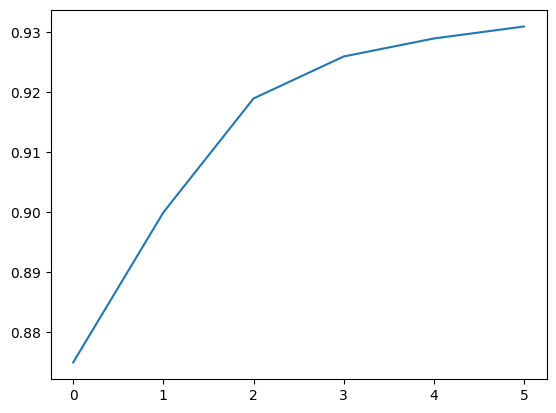

In [ ]:
#plot with some synthetic values
yields = [0.875, 0.900, 0.919, 0.926, 0.929, 0.931]

plt.plot(yields)
plt.show()

Look at the x axis. You gave Matplotlib six numbers and no x values, so
it used the **positions** of the items: 0, 1, 2, 3, 4, 5. A single list
is always read as y values.

If you want meaningful x values, pass two lists. The first is x, the
second is y.

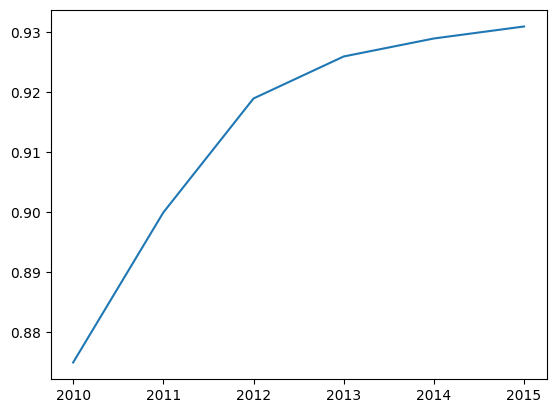

In [ ]:
# two plain Python lists: x values and y values
years = [2010, 2011, 2012, 2013, 2014, 2015]

plt.plot(years, yields)
plt.show()

### More than one line

To draw a second line, call `plt.plot` again. Matplotlib picks a
different colour for you, and `plt.legend` says which is which.

In [ ]:
# three series on one chart: call plt.plot once for each
wheat = [0.962, 0.941, 0.930, 0.923, 0.918, 0.908]

plt.plot(years, yields, label="Barley")
plt.plot(years, wheat, label="Wheat")
plt.legend()
plt.show()

NameError: name 'years' is not defined

Two things worth noticing, because both come back later with real data.
Matplotlib chose the colours from a built-in sequence, so two lines are
distinguishable without you asking. And the legend was built from the
`label` you attached to each line: no labels, no legend.

**&#9998; Exercise.** Make a list of the numbers 1 to 10 and a second list of their squares.
>
> 1.  Plot the squares against the numbers.
> 2.  Add a title and label both axes, using `plt.title`,
>     `plt.xlabel` and `plt.ylabel`.

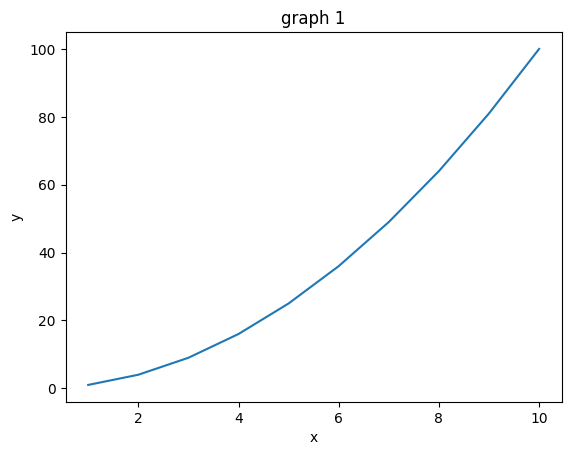

In [ ]:
import matplotlib.pyplot as plt


list1 = [i for i in range(1,11)]
list2 = [i**2  for i in list1]


plt.plot(list1,list2)
plt.title('graph 1')
plt.xlabel('x')
plt.ylabel('y')

plt.show()

# 3. Getting the World Bank Data (wbdata)

**`wbdata`** is a Python
package for the World Bank's data API. It already handle the `requests` work for
you (recall Part 4) and hands back a pandas DataFrame.

Read more here: https://wbdata.readthedocs.io/en/stable/

You will need to install this package, and might be asked to restart the session after the installation.

In [ ]:
# wbdata is NOT pre-installed in Colab, so this one is needed.
# If Colab asks you to restart the session afterwards, do it.
!pip install wbdata

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 8.7 MB/s eta 0:00:00
  Attempting uninstall: decorator
    Found existing installation: decorator 4.4.2
    Uninstalling decorator-4.4.2:
      Successfully uninstalled decorator-4.4.2
  Attempting uninstall: cachetools
    Found existing installation: cachetools 6.2.6
    Uninstalling cachetools-6.2.6:
      Successfully uninstalled cachetools-6.2.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [ ]:
# pandas holds the table, numpy does the numeric work
import wbdata
import pandas as pd
import numpy as np

## 3.1 Choosing indicators and countries

The World Bank publishes thousands of **indicators**, each with a code.
In this example, we will use the following four:

| Code | What it measures |
|---|---|
| `NY.GDP.PCAP.KD` | GDP per capita, constant 2015 US$ |
| `NY.GDP.PCAP.KD.ZG` | GDP per capita growth, annual % |
| `SP.DYN.LE00.IN` | Life expectancy at birth, years |
| `SP.POP.TOTL` | Total population |

Countries are given as three letter codes.

In [ ]:
# the keys are World Bank indicator codes, the values are the
# column names we want them to have in the DataFrame
indicators = {
    "NY.GDP.PCAP.KD": "gdp_per_capita",
    "NY.GDP.PCAP.KD.ZG": "gdp_growth",
    "SP.DYN.LE00.IN": "life_expectancy",
    "SP.POP.TOTL": "population",
}

countries = ["GBR", "FRA", "ESP", "ITA", "NLD",
             "CHN", "ARE", "IND", "JOR", "USA"]

Now we ask for the data. Notice what the `indicators` dictionary is
doing: the keys are sent to the World Bank, the values become the
column names. One dictionary both asks the question and labels the
answer.

The result arrives with country and date as the index, so
`reset_index()` turns them into ordinary columns, and the date comes
back as text, so `.astype(int)` makes it a number as in Part 3.

In [ ]:
# retrieving the desired data
df = wbdata.get_dataframe(indicators,
                          country=countries,
                          date=("2000", "2025"))

# process the data frame
df = df.reset_index()
df = df.rename(columns={"date": "year"})
df["year"] = df["year"].astype(int)

Before plotting anything, look at what you have. You may see there are NaN (Not a Number) for some cells!

In [ ]:
# always look at the table before plotting it
print("number of rows and columns:", df.shape)
df.head()

number of rows and columns: (260, 8)


,country,year,gdp_per_capita,gdp_growth,life_expectancy,population,region,income
0,United Arab Emirates,2025,NaN,NaN,NaN,11513149.0,"Middle East, North Africa, Afghanistan & Pakistan",High income
1,United Arab Emirates,2024,41605.413871,-0.766014,83.069,10986400.0,"Middle East, North Africa, Afghanistan & Pakistan",High income
2,United Arab Emirates,2023,41926.577350,0.234310,82.909,10483751.0,"Middle East, North Africa, Afghanistan & Pakistan",High income
3,United Arab Emirates,2022,41828.568692,2.180671,80.487,10074977.0,"Middle East, North Africa, Afghanistan & Pakistan",High income
4,United Arab Emirates,2021,40935.891548,2.651619,79.083,9575152.0,"Middle East, North Africa, Afghanistan & Pakistan",High income


## 3.2 Adding regions and income groups

The country column already holds full names, because that is what
`wbdata` puts in the index. Regions and income groups are not in the
same response: they come from a different part of the API, which is
normal. One table holds the measurements, another holds facts about
the countries, and you join them.

`wbdata.get_countries` returns a record per country. Two dictionary
comprehensions turn those into lookups and `.map` applies them, the
same pattern as Part 3.

In [ ]:
#get the names of the countries
info = wbdata.get_countries(countries)

# Enrich the DataFrame with regions and income levels using country names
region_of = {c["name"]: c["region"]["value"] for c in info}
income_of = {c["name"]: c["incomeLevel"]["value"] for c in info}

df["region"] = df["country"].map(region_of)
df["income"] = df["country"].map(income_of)

df.head()

,country,year,gdp_per_capita,gdp_growth,life_expectancy,population
0,United Arab Emirates,2025,NaN,NaN,NaN,11513149.0
1,United Arab Emirates,2024,41605.413871,-0.766014,83.069,10986400.0
2,United Arab Emirates,2023,41926.577350,0.234310,82.909,10483751.0
3,United Arab Emirates,2022,41828.568692,2.180671,80.487,10074977.0
4,United Arab Emirates,2021,40935.891548,2.651619,79.083,9575152.0


> **If the API is slow or blocked.** There is a copy of this table on
> Blackboard as `wb_indicators.csv`. Replace the two cells above with:
>
> ```python
> df = pd.read_csv("wb_indicators.csv")
> ```

# 4. Plotting One country over time

Similar to the synthetic data, `plt.plot` still
takes x values and y values. The only new step is getting them out of
the DataFrame, by filtering it down to one country with the comparison, then naming the two columns you want.

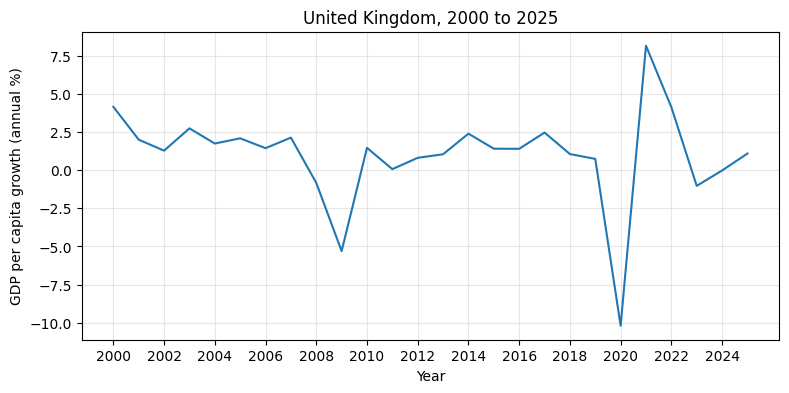

In [ ]:
# keep only the rows for one country
uk = df[df["country"] == "United Kingdom"]

plt.figure(figsize=(9, 4))

plt.plot(uk["year"], uk["gdp_growth"])
plt.xlabel("Year")
plt.xticks(np.arange(2000,2026,2))
plt.ylabel("GDP per capita growth (annual %)")
plt.title("United Kingdom, 2000 to 2025")
plt.grid(True, alpha=0.3)

plt.show()

`plt.grid` adds grid lines, which make it easier to read a value off the
chart. `alpha` sets how opaque something is, from 0 to 1. Faint grid
lines help without competing with the data.

> **&#9998; Exercise.** Draw the same chart for India, then for China. What happened in 2020?

Mounted at /content/drive
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   country          260 non-null    object 
 1   year             260 non-null    int64  
 2   gdp_per_capita   259 non-null    float64
 3   gdp_growth       259 non-null    float64
 4   life_expectancy  250 non-null    float64
 5   population       260 non-null    float64
 6   region           260 non-null    object 
 7   income           260 non-null    object 
dtypes: float64(4), int64(1), object(3)
memory usage: 16.4+ KB


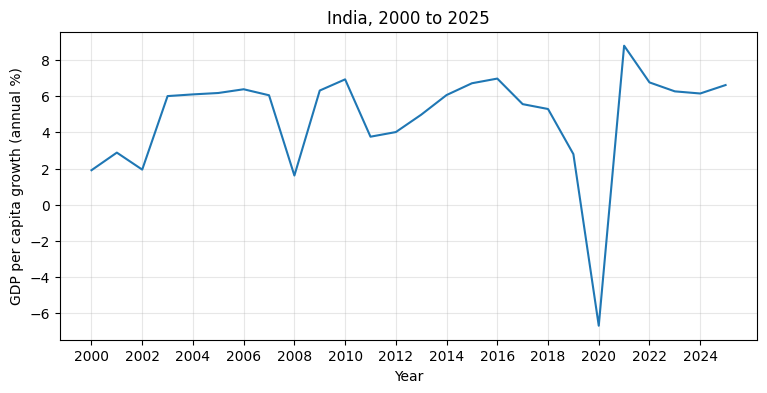

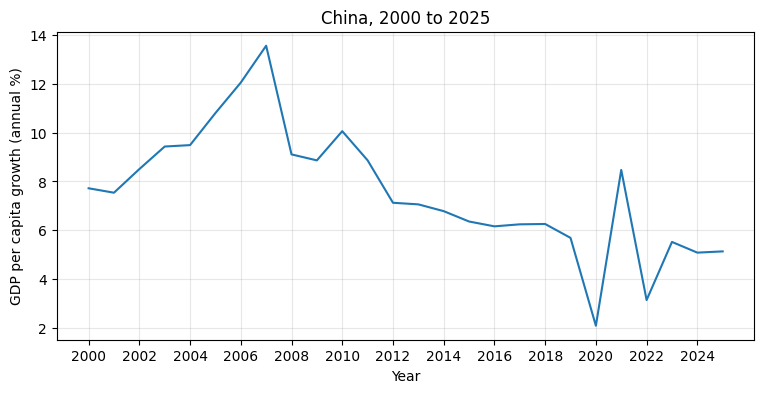

In [ ]:
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")

df = pd.read_csv("/content/drive/MyDrive/Material/wb_indicators.csv")

df.info()


India = df[df["country"] == "India"]

plt.figure(figsize=(9, 4))

plt.plot(India["year"], India["gdp_growth"])
plt.xlabel("Year")
plt.xticks(np.arange(2000,2026,2))
plt.ylabel("GDP per capita growth (annual %)")
plt.title("India, 2000 to 2025")
plt.grid(True, alpha=0.3)

plt.show()


China = df[df["country"] == "China"]

plt.figure(figsize=(9, 4))

plt.plot(China["year"], China["gdp_growth"])
plt.xlabel("Year")
plt.xticks(np.arange(2000,2026,2))
plt.ylabel("GDP per capita growth (annual %)")
plt.title("China, 2000 to 2025")
plt.grid(True, alpha=0.3)

plt.show()

# 5. Several countries at once

Two lines meant calling `plt.plot` twice. Ten lines would mean ten
calls, so a `for` loop comes in handy here: in each iteration one line is plotted.

`label=name` is the same `label` as before, and it is still what the
legend is built from.

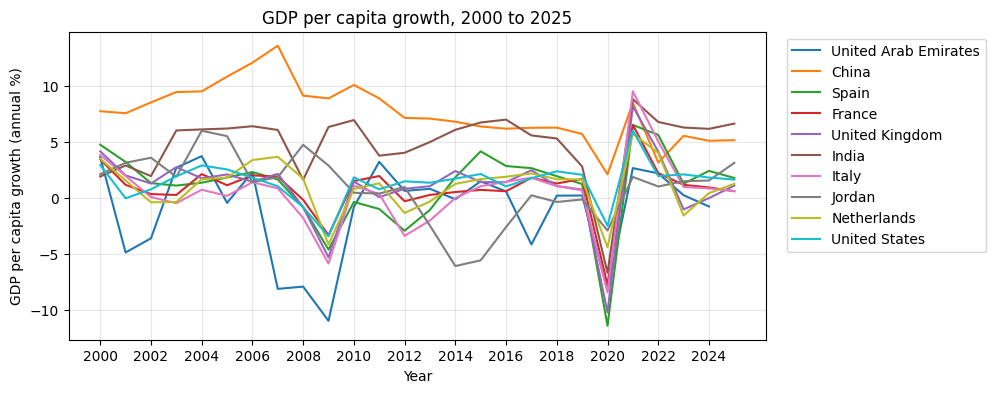

In [ ]:
# one line per country: filter the table, then plot that slice
plt.figure(figsize=(9, 4))

for name in df["country"].unique():
    sub = df[df["country"] == name]
    plt.plot(sub["year"], sub["gdp_growth"], label=name)

plt.xlabel("Year")
plt.xticks(np.arange(2000,2026,2))
plt.ylabel("GDP per capita growth (annual %)")
plt.title("GDP per capita growth, 2000 to 2025")
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.show()

`bbox_to_anchor=(1.02, 1)` puts the legend just outside the right hand
edge of the axes, so it does not sit on top of the data. With ten
countries there is nowhere inside the chart for it to go.

Leave the `label` out and Matplotlib cannot build a legend. It does not
stop, it warns and draws an empty box. Have a try on the code above by removing the label.

> **&#9998; Exercise.** Draw one chart showing life expectancy over time for all ten countries,
> with a legend outside the plotting area and both axes labelled.

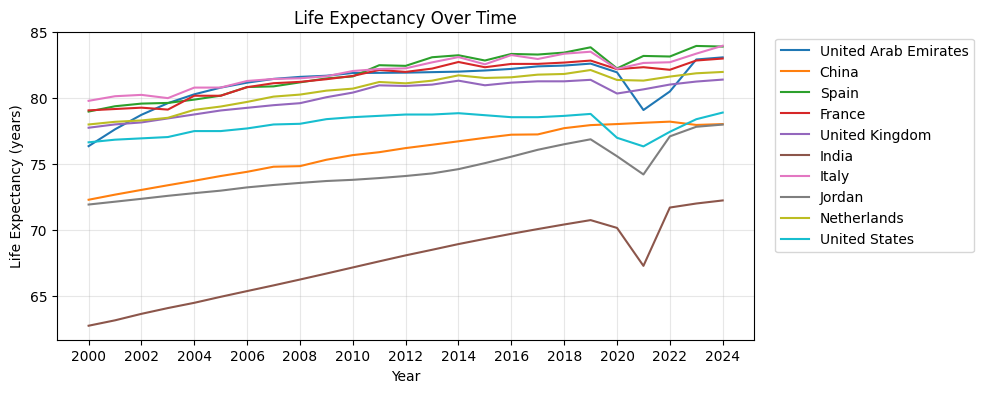

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 4))

for name in df["country"].unique():
    sub = df[df["country"] == name]
    plt.plot(sub["year"], sub["life_expectancy"], label=name)

plt.xlabel("Year")
plt.xticks(np.arange(2000,2026,2))
plt.ylabel("Life Expectancy (years)")
plt.title("Life Expectancy Over Time")
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.show()

# 6. Legends

The chart above put its legend outside the plotting area with
`bbox_to_anchor`, which was not explained at the time. Legends are
worth a section of their own, because a badly placed one hides the
data it is meant to explain.

`plt.legend()` takes a long list of arguments. The ones that matter
most:

| Argument | Effect |
|---|---|
| `loc` | position inside the axes, e.g. `"upper right"`, `"best"` |
| `bbox_to_anchor` | position relative to the axes, for putting it outside |
| `title` | a heading above the entries |
| `frameon` | whether to draw the box |
| `ncol` | spread entries over several columns |
| `framealpha` | how opaque the box is |

With a handful of series there is usually room inside the chart.

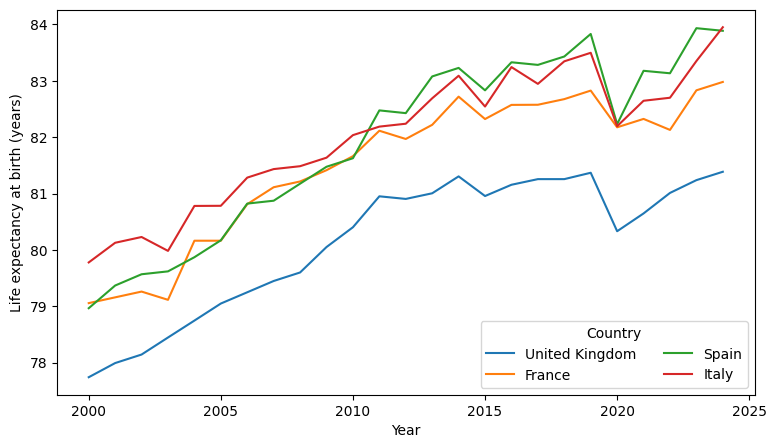

In [ ]:
# four countries only, so a legend inside the chart still fits
plt.figure(figsize=(9, 5))

for name in ["United Kingdom", "France", "Spain", "Italy"]:
    # pull out one country's rows, then draw a line for it
    sub = df[df["country"] == name]
    plt.plot(sub["year"], sub["life_expectancy"], label=name)

plt.xlabel("Year")
plt.ylabel("Life expectancy at birth (years)")

# loc puts the box inside the axes, ncol spreads the entries over
# two columns, and framealpha makes the box slightly see-through
plt.legend(title="Country",
           loc="lower right",
           frameon=True,
           framealpha=0.8,
           ncol=2)

plt.show()

`label=` in each `plt.plot` call is what the legend reads. Without it
there is nothing for `plt.legend()` to list.

With ten series a legend inside the axes covers the data, which is why
the chart before this one moved it out:

```python
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
```

`bbox_to_anchor` gives a point in **axes coordinates**, where `(0, 0)`
is the bottom left corner of the plotting area and `(1, 1)` the top
right. So `(1.02, 1)` is just outside the right edge, level with the
top. `loc` then says which corner of the legend box sits on that point.

# 7. Lines, markers and colours

`plt.plot` takes a long list of styling arguments. The ones worth
knowing:

| Argument | Short form | Sets |
|---|---|---|
| `color` | `c` | the colour of the line |
| `linestyle` | `ls` | solid, dashed, dotted |
| `linewidth` | `lw` | how thick the line is |
| `marker` | | the symbol drawn at each data point |
| `markersize` | `ms` | how big those symbols are |
| `alpha` | | opacity, from 0 to 1 |

Common markers are `o` for a circle, `s` for a square, `^` for a
triangle and `D` for a diamond. The full lists are in the Matplotlib
documentation for
[markers](https://matplotlib.org/stable/api/markers_api.html) and
[line styles](https://matplotlib.org/stable/gallery/lines_bars_and_markers/linestyles.html).

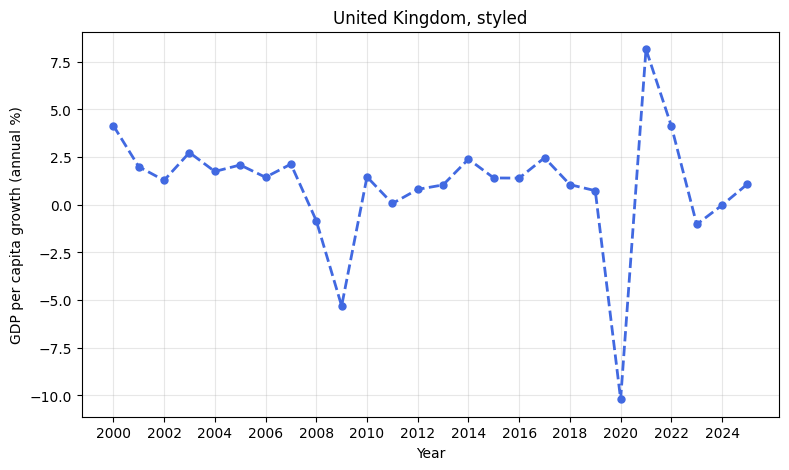

In [ ]:
# every styling argument set on its own line, so you can see
# which is which
plt.figure(figsize=(9, 5))

plt.plot(uk["year"], uk["gdp_growth"],
         color="royalblue",
        linestyle="--",
        linewidth=2,
        marker="o",
        markersize=5)

plt.xlabel("Year")
plt.xticks(np.arange(2000,2026,2))
plt.ylabel("GDP per capita growth (annual %)")
plt.title("United Kingdom, styled")
plt.grid(True, alpha=0.3)

plt.show()

## 7.1 The format string, and the trap in it

There is a shorthand that packs marker, line style and colour into one
string, given straight after the data:

```python
fmt = "[marker][line][colour]"
```

So `"o-r"` means circles, a solid line, red. It is quick, but be careful it is
a trap in a loop.

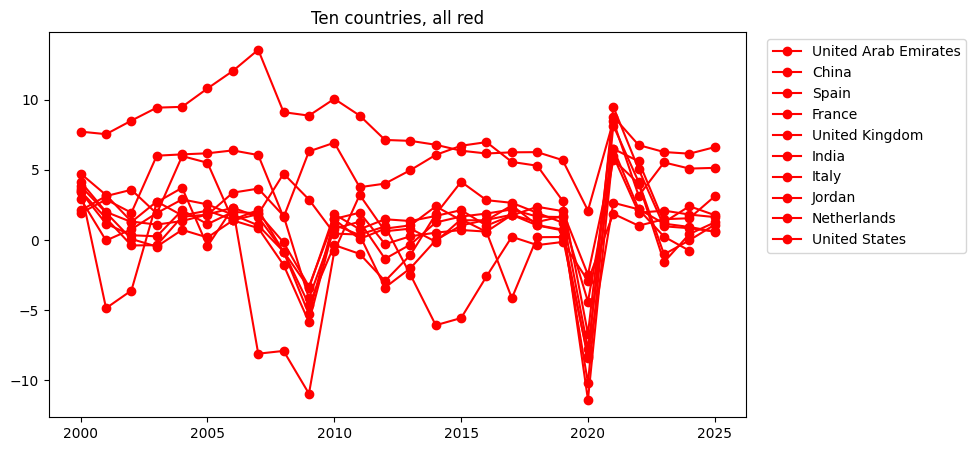

In [ ]:
# deliberate error: "o-r" fixes the colour, so every line is red
plt.figure(figsize=(9, 5))

for name in df["country"].unique():
    sub = df[df["country"] == name]
    plt.plot(sub["year"], sub["gdp_growth"], "o-r", label=name)

plt.title("Ten countries, all red")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.show()

Every line is red, so the chart says nothing about which country is
which, and the legend lists ten identical red entries. The format
string fixed the colour for every call.

The rest of this section is about setting a colour deliberately, and
about what Matplotlib does when you do not.

## 7.2 Naming a colour

The simplest way to set a colour is to name it. Matplotlib knows
several hundred names, listed in its
[named colours](https://matplotlib.org/stable/gallery/color/named_colors.html)
gallery.

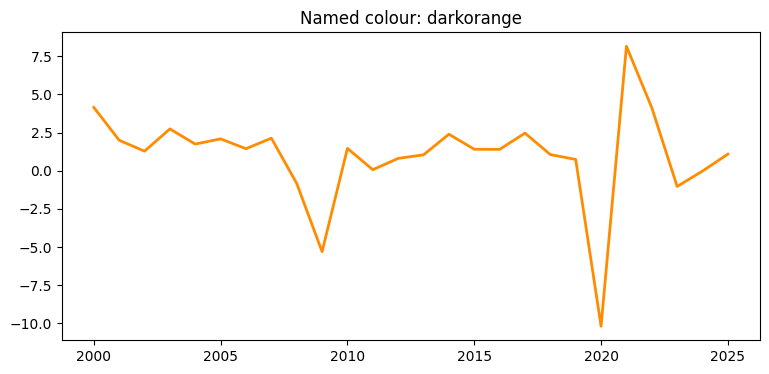

In [ ]:
# color= takes a name, a hex code or an RGB tuple
plt.figure(figsize=(9, 4))

plt.plot(uk["year"], uk["gdp_growth"], color="darkorange", linewidth=2)
plt.title("Named colour: darkorange")

plt.show()

## 7.3 Hexadecimal codes and RGB

For an exact colour, give a **hexadecimal code** in the form
`#RRGGBB`. Each pair is one of red, green and blue, from `00` to `FF`,
which gives 16,777,216 possible colours. `#FF0000` is pure red,
`#000000` black, `#FFFFFF` white.

You can also give the three channels as a tuple of fractions from 0
to 1. `(1.0, 0.0, 0.0)` is the same pure red. Dividing each of the
usual 0 to 255 values by 255 converts between the two.

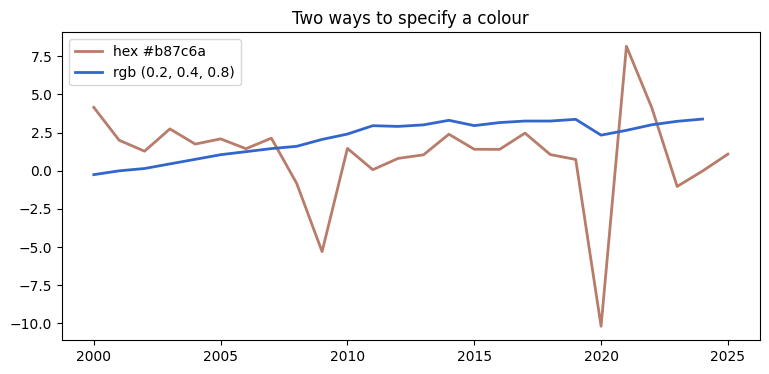

In [ ]:
plt.figure(figsize=(9, 4))

# a hex code: #b8 red, #7c green, #6a blue
plt.plot(uk["year"], uk["gdp_growth"], color="#b87c6a", linewidth=2,
         label="hex #b87c6a")

# the same idea as three fractions; the - 78 just shifts the second
# series down so both fit on one set of axes
plt.plot(uk["year"], uk["life_expectancy"] - 78, color=(0.2, 0.4, 0.8),
         linewidth=2, label="rgb (0.2, 0.4, 0.8)")

plt.legend()
plt.title("Two ways to specify a colour")

plt.show()

## 7.4 Letting Matplotlib choose

If you do not set a colour, Matplotlib works through its **colour
cycle**, a set of ten colours chosen to be distinguishable from one
another. That is why the loop in section 5 produced ten different
lines without you doing anything, and why the format string above
broke it: `"o-r"` fixed the colour for every call.

This is a good default. Take control when you need a specific meaning
attached to a specific colour. The next session covers doing that
systematically, with **colormaps**.

# every styling argument set on its own line, so you can see
# which is which
plt.figure(figsize=(9, 5))

plt.plot(uk["year"], uk["gdp_growth"],
         color="royalblue",
        linestyle="--",
        linewidth=2,
        marker="o",
        markersize=5)

plt.xlabel("Year")
plt.xticks(np.arange(2000,2026,2))
plt.ylabel("GDP per capita growth (annual %)")
plt.title("United Kingdom, styled")
plt.grid(True, alpha=0.3)

plt.show()

> **&#9998; Exercise.** Plot the GDP per capita of Spain and Italy on one chart, Spain with a
> solid line and Italy dashed, each with a different marker, and a legend
> naming them.
>
> Then set each country's colour explicitly, once with a named colour
> and once with a hex code.

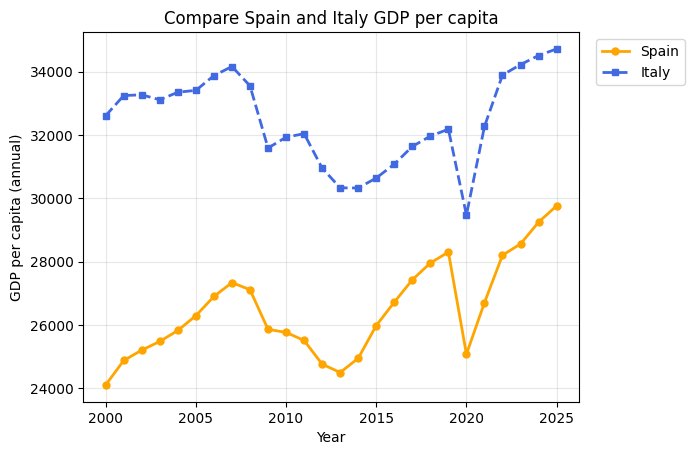

In [ ]:
# Spain
Spain = df[df['country'] == 'Spain']
plt.plot(Spain["year"], Spain["gdp_per_capita"], color="orange", linestyle="-", linewidth=2, marker="o", markersize=5,label='Spain')

#Italy
Italy =  df[df['country'] == 'Italy']
plt.plot(Italy["year"], Italy["gdp_per_capita"], color="royalblue", linestyle="--", linewidth=2, marker="s", markersize=5, label='Italy')

plt.legend()
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("Compare Spain and Italy GDP per capita")
plt.xlabel("Year")
plt.ylabel("GDP per capita (annual)")
plt.grid(True, alpha=0.3)

plt.show()

# 8. Scatter plots

A line chart joins the points in order, which only makes sense when the
x axis has an order to it, usually time. When you want to compare two
measurements across many cases at one moment, use a **scatter plot**
and draw the points without joining them.

Here is population against life expectancy for the most recent year in
our data.

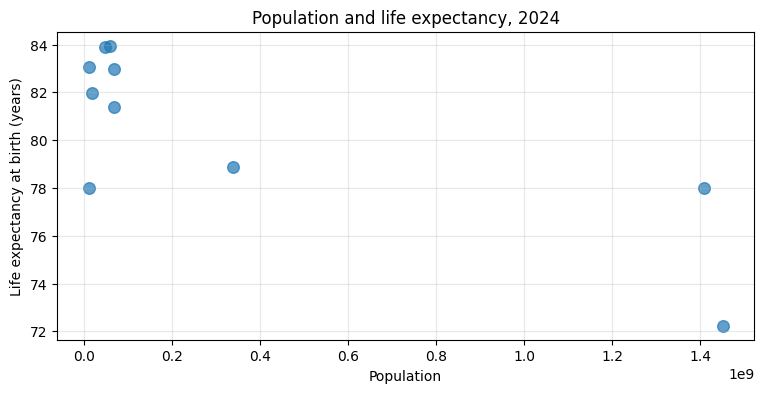

In [ ]:
# 2024 is the latest year with life expectancy data
latest = df[df["year"] == 2024]

plt.figure(figsize=(9, 4))

plt.scatter(latest["population"], latest["life_expectancy"],
            s=70, alpha=0.7)

plt.xlabel("Population")
plt.ylabel("Life expectancy at birth (years)")
plt.title("Population and life expectancy, 2024")
plt.grid(True, alpha=0.3)

plt.show()

Most of the points are crushed against the left hand edge, because
two countries (which two?) are two orders of magnitude larger than the
others. A **logarithmic** x axis spreads them out: each step along
the axis is a multiplication rather than an addition.

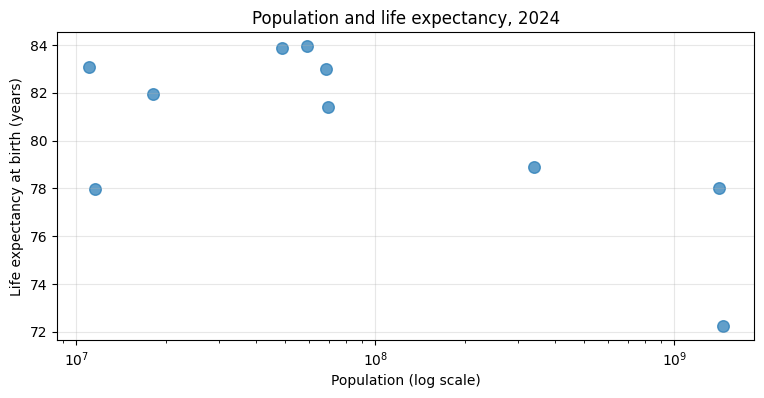

In [ ]:
# the same chart again, with a log scale on the x axis
plt.figure(figsize=(9, 4))

plt.scatter(latest["population"], latest["life_expectancy"],
            s=70, alpha=0.7)

plt.xscale("log")
plt.xlabel("Population (log scale)")
plt.ylabel("Life expectancy at birth (years)")
plt.title("Population and life expectancy, 2024")
plt.grid(True, alpha=0.3)

plt.show()

> A log scale is a real change to what the chart says, not a cosmetic
> one. Always label the axis clearly so the reader knows!

**&#9998; Exercise.** Make a scatter plot of GDP per capita against life expectancy for 2024,
> with a log scale on the x axis. Does the relationship look linear?
>

<class 'wbdata.client.DataFrame'>
Index: 10 entries, 1 to 235
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   country          10 non-null     object 
 1   year             10 non-null     int64  
 2   gdp_per_capita   10 non-null     float64
 3   gdp_growth       10 non-null     float64
 4   life_expectancy  10 non-null     float64
 5   population       10 non-null     float64
dtypes: float64(4), int64(1), object(1)
memory usage: 560.0+ bytes


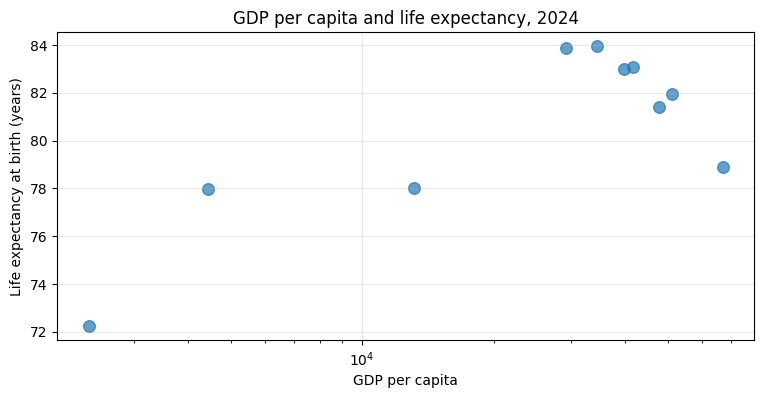

In [ ]:
# 2024 is the latest year with life expectancy data
latest.info()

latest = df[df["year"] == 2024]

plt.figure(figsize=(9, 4))

plt.scatter(latest["gdp_per_capita"], latest["life_expectancy"],
            s=70, alpha=0.7)

plt.xscale("log")
plt.xlabel("GDP per capita")
plt.ylabel("Life expectancy at birth (years)")
plt.title("GDP per capita and life expectancy, 2024")
plt.grid(True, alpha=0.3)

plt.show()

# 9. Titles, subtitles and captions

A good chart title says what the reader should take away, not what the
chart contains. "GDP per capita growth by country" describes the axes,
which the reader can already see. "Growth has not recovered to its
pre-2008 level" tells them something.

A useful pattern is a short headline, a longer subtitle for context,
and a caption underneath for the source:

*   `plt.suptitle` for the headline, across the whole image
*   `plt.title` with `loc="left"` for the subtitle
*   `plt.figtext` for the caption

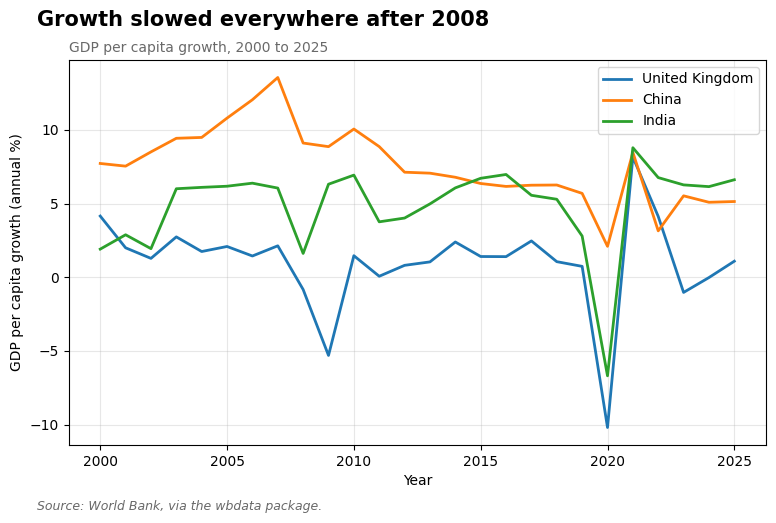

In [ ]:
plt.figure(figsize=(9, 5))

for name in ["United Kingdom", "China", "India"]:
    sub = df[df["country"] == name]
    plt.plot(sub["year"], sub["gdp_growth"], label=name, linewidth=2)

plt.xlabel("Year")
plt.ylabel("GDP per capita growth (annual %)")
plt.legend()
plt.grid(True, alpha=0.3)

# the headline, in bold across the whole image
plt.suptitle("Growth slowed everywhere after 2008",
             x=0.09, ha="left", fontsize=15, fontweight="bold")

# the subtitle, smaller and grey, sitting above the axes
plt.title("GDP per capita growth, 2000 to 2025",
          loc="left", fontsize=10, color="dimgray")

# the caption, below the bottom of the image
plt.figtext(0.09, -0.02,
            "Source: World Bank, via the wbdata package.",
            ha="left", fontsize=9, style="italic", color="dimgray")

plt.show()

> The `x` and `y` positions in `plt.suptitle` and `plt.figtext` are given
> in **figure coordinates**: 0 is the left or bottom edge of the whole
> image and 1 is the right or top. They are not data values, which is
> why a caption can sit at `-0.02`, just below the image.

> **&#9998; Exercise.** Write a title and subtitle for the scatter plot
> you drew in the last section. The title should be a short sentence
> making a claim the chart supports. Add a caption giving the source and
> your name.
>
> Then redraw the ten-country chart from section 5, and move its legend
> to sit above the chart spread over three columns, using
> `bbox_to_anchor` and `ncol`.

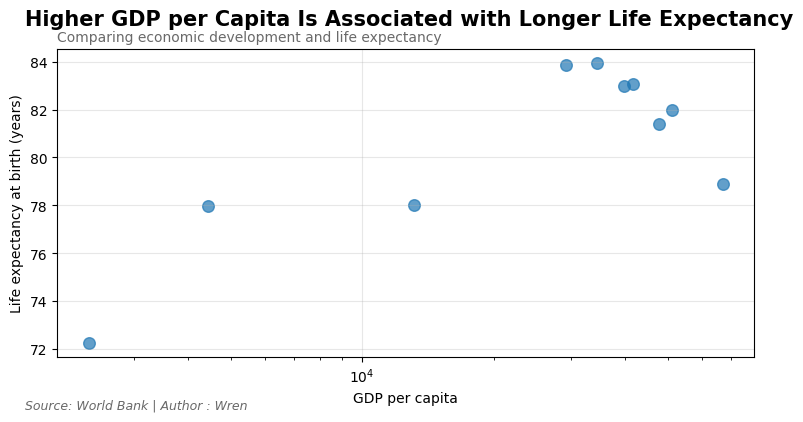

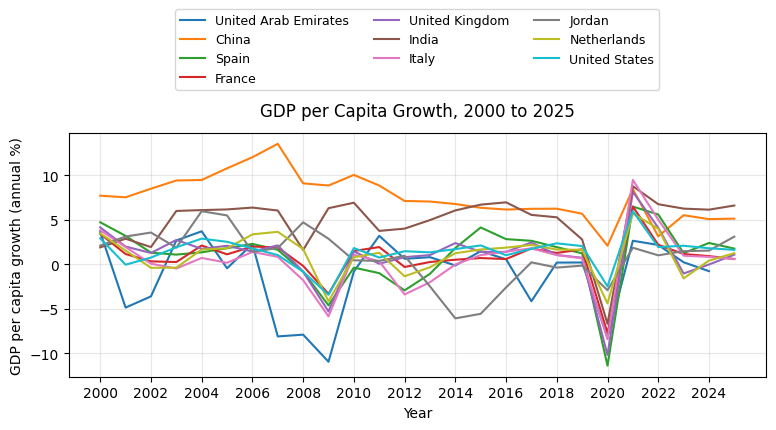

In [ ]:
# ---- 1 ----
# Write a title and subtitle for the scatter plot you drew in the last section

latest = df[df["year"] == 2024]

plt.figure(figsize=(9, 4))
plt.scatter(latest["gdp_per_capita"], latest["life_expectancy"],
            s=70, alpha=0.7)

plt.xscale("log")
plt.xlabel("GDP per capita")
plt.ylabel("Life expectancy at birth (years)")

plt.grid(True, alpha=0.3)

# the headline, in bold across the whole image
plt.suptitle("Higher GDP per Capita Is Associated with Longer Life Expectancy",
             x=0.09, ha="left", fontsize=15, fontweight="bold")

# the subtitle, smaller and grey, sitting above the axes
plt.title("Comparing economic development and life expectancy",
          loc="left", fontsize=10, color="dimgray")

# the caption, below the bottom of the image
plt.figtext(0.09, -0.02,
            "Source: World Bank | Author : Wren",
            ha="left", fontsize=9, style="italic", color="dimgray")

plt.show()


# ---- 2 ----
# redraw the ten-country chart from section 5

fig, ax = plt.subplots(figsize=(9, 4))

for name in df["country"].unique():
    sub = df[df["country"] == name]
    ax.plot(sub["year"], sub["gdp_growth"], label=name)

ax.set_xlabel("Year")
ax.set_xticks(np.arange(2000, 2026, 2))
ax.set_ylabel("GDP per capita growth (annual %)")
ax.set_title("GDP per Capita Growth, 2000 to 2025", pad=12)
ax.grid(True, alpha=0.3)

# Legend above the chart, arranged in 3 columns
ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=3,
    fontsize=9
)

# Reserve space at the top for the legend and title
fig.subplots_adjust(top=0.72)

plt.show()

# 10. Saving your chart

`plt.savefig` writes the chart to a file. Two arguments are worth
setting every time:

*   `dpi` controls the resolution. 200 is fine for a report, 300 for
    print.
*   `bbox_inches="tight"` trims the surrounding whitespace, and stops
    labels being cut off at the edges.

The saved file can be found by clicking the `Files` icon on the left hand side (second to last). You might need to refresh the Files (the second button). You can then download it to your computer.

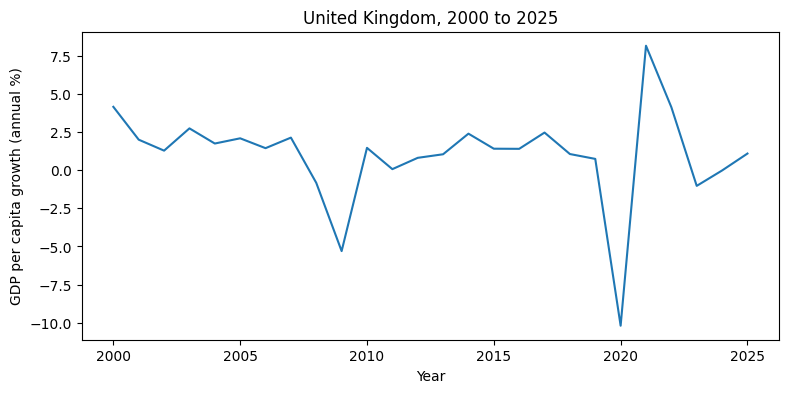

In [ ]:
# draw the chart and save it in the same cell, before plt.show
plt.figure(figsize=(9, 4))

plt.plot(uk["year"], uk["gdp_growth"])
plt.xlabel("Year")
plt.ylabel("GDP per capita growth (annual %)")
plt.title("United Kingdom, 2000 to 2025")

plt.savefig("uk_growth.png", dpi=200, bbox_inches="tight")
plt.show()

## 10.1 Saving the correct chart

`plt.savefig` saves the **current** chart, and `plt.figure()` makes a
new one current. Draw a chart, let another `plt.figure()` run before you
save, and you save the empty one instead. Nothing goes wrong and no
error appears. You just get a blank image.

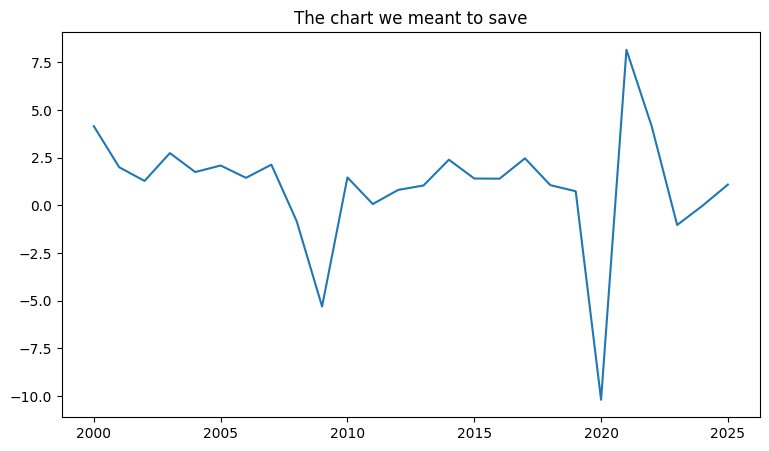

<Figure size 640x480 with 0 Axes>

In [ ]:
# deliberate error: saves a blank image, with no warning

# the chart we actually want
plt.figure(figsize=(9, 5))
plt.plot(uk["year"], uk["gdp_growth"])
plt.title("The chart we meant to save")

# a new, empty figure. THIS one is now the current one
plt.figure()

# so savefig writes the empty figure, not the chart above it
plt.savefig("empty.png", dpi=200)
plt.show()

In [ ]:
# the blank file is a fraction of the size, which is the quickest
# way to spot the mistake
import os

for name in ["uk_growth.png", "empty.png"]:
    print(name, os.path.getsize(name), "bytes")

uk_growth.png 82890 bytes
empty.png 7138 bytes


## 10.2 Downloading the files (with code)

You can also download it with code,

```python
from google.colab import files
files.download("uk_growth.png")
```

or mount your Google Drive as in Part 4 and save it there:

```python
from google.colab import drive
drive.mount("/content/drive")

plt.savefig("/content/drive/MyDrive/uk_growth.png",
            dpi=200, bbox_inches="tight")
```

> **&#9998; Exercise.** Save the scatter plot you made earlier as a PNG at 300 dpi, then
> download it.

/tmp/ipykernel_6115/340804135.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(


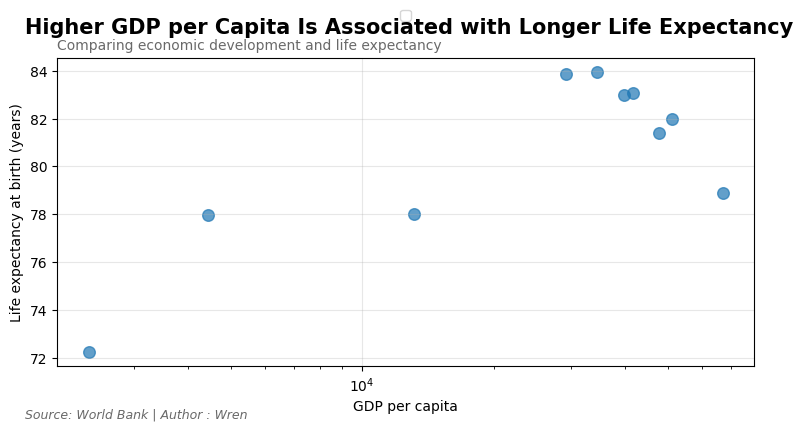

In [ ]:
# Prepare scatter plot
latest = df[df["year"] == 2024]

plt.figure(figsize=(9, 4))
plt.scatter(latest["gdp_per_capita"], latest["life_expectancy"],
            s=70, alpha=0.7)

plt.xscale("log")
plt.xlabel("GDP per capita")
plt.ylabel("Life expectancy at birth (years)")

plt.grid(True, alpha=0.3)

plt.suptitle("Higher GDP per Capita Is Associated with Longer Life Expectancy",
             x=0.09, ha="left", fontsize=15, fontweight="bold")


plt.title("Comparing economic development and life expectancy",
          loc="left", fontsize=10, color="dimgray")

plt.figtext(0.09, -0.02,
            "Source: World Bank | Author : Wren",
            ha="left", fontsize=9, style="italic", color="dimgray")

plt.legend(
    bbox_to_anchor=(0.5, 1.18),
    loc="upper center",
    ncol=3
)
plt.show()

# save
plt.savefig("/content/drive/MyDrive/Result/scatter_plot.png", dpi=300)


In [ ]:
# Download
from google.colab import files
files.download("/content/drive/MyDrive/Result/scatter_plot.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 11. Take home exercise

Pick a different set of at least five countries, and one indicator that
is not one of the four above. The World Bank's
[indicator list](https://data.worldbank.org/indicator) is searchable,
and the code appears in the page's web address.

1.  Load the data for your selected countries and your selected indicator from 2000 to
    2025.
2.  Draw a line chart with one line per country.
3.  Label both axes, give the chart a title, add faint grid lines, and
    put a legend outside the plotting area.
4.  Give each line a marker.
5.  Save the chart as a PNG at 300 dpi and download it.

Keep this notebook. The next session picks up where it stops.

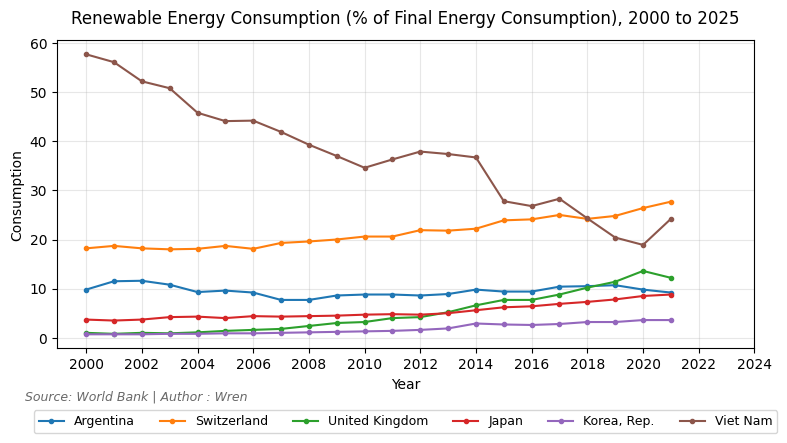

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 640x480 with 0 Axes>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from google.colab import files

# 1. choose the countries and indicator
countries = {
    "ARG": "Argentina",
    "JPN": "Japan",
    "KOR" : "Korea",
    "GBR": "United Kingdom",
    "CHE": "Switzerland",
    "VNM": "Viet Nam"
}
#https://data.worldbank.org/indicator/EG.FEC.RNEW.ZS

indicator = "EG.FEC.RNEW.ZS"
indicator_name = "Renewable Energy Consumption (% of Final Energy Consumption)"

# 2. Get data from the World Bank API
country_codes = ";".join(countries.keys())

url = f"https://api.worldbank.org/v2/country/{country_codes}/indicator/{indicator}"

params = {
    "date": "2000:2025",
    "format": "json",
    "per_page": 2000
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

data = response.json()

# Convert the API response into DataFrame
records = []


for item in data[1]:
    if item["value"] is not None:
        records.append({
            "country": item["country"]["value"],
            "year": int(item["date"]),
            "value": item["value"]
        })

df2 = pd.DataFrame(records)


# 4. Draw  line graph
fig, ax = plt.subplots(figsize=(9, 4))

for name in df2["country"].unique():
    sub = df2[df2["country"] == name]
    ax.plot(sub["year"], sub["value"], marker = 'o', markersize=3, label=name)

ax.set_xlabel("Year")
ax.set_xticks(np.arange(2000, 2026, 2))
ax.set_ylabel('Consumption')
ax.set_title(f"{indicator_name}, 2000 to 2025", pad=12)
ax.grid(True, alpha=0.3)
plt.figtext(0.09, -0.02,
            "Source: World Bank | Author : Wren",
            ha="left", fontsize=9, style="italic", color="dimgray")


# Legend above the chart, arranged in 3 columns
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=6,
    fontsize=9
)

plt.show()


# 5. Save the chart as PNG
filename = "/content/drive/MyDrive/Result/renewable_energy_consumption.png"

plt.savefig(
    filename,
    dpi=300,
    bbox_inches="tight"
)


# 6. Download the PNG file
files.download(filename)
